# Phase 2 — Notebook 2: 3-Qubit Phase-Flip Error Correction Code

## What this notebook does:
We build a circuit that **protects a qubit against phase-flip errors** using 3 qubits.

## How is this different from the Bit-Flip code?
Only ONE change: we **wrap the entire circuit in Hadamard gates**.

Why? Because:
- The Hadamard gate (H) converts phase-flips (Z errors) into bit-flips (X errors)
- So we: H → use the same bit-flip correction → H again
- The phase-flip gets temporarily converted to a bit-flip, gets corrected, then converted back

## Same measurements as Notebook 1:
- Logical error rate vs Physical error rate
- Fidelity after correction
- Pseudo-threshold (breakeven point)

---
## Step 1: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector, state_fidelity

from qiskit_aer import AerSimulator
from qiskit_aer.noise import (
    NoiseModel,
    pauli_error,
    depolarizing_error,
    amplitude_damping_error,
)

plt.rcParams['figure.dpi'] = 110
np.random.seed(42)

print('Libraries loaded!')

Libraries loaded!


---
## Step 2: Build the Phase-Flip Correction Circuit

Compare this with the Bit-Flip code. The ONLY differences are marked with `# ← NEW`.
Everything else is identical.

```
Bit-Flip:   Prepare → Encode → Noise → Syndrome → Correct → Decode → Measure
Phase-Flip: Prepare → H → Encode → Noise → Syndrome → Correct → Decode → H → Measure
                       ↑                                                   ↑
                    NEW: Hadamard before                          NEW: Hadamard after
```

Total qubits: 5 (3 data + 2 ancilla)
Only difference from bit-flip: Hadamard gates before encoding and after decoding



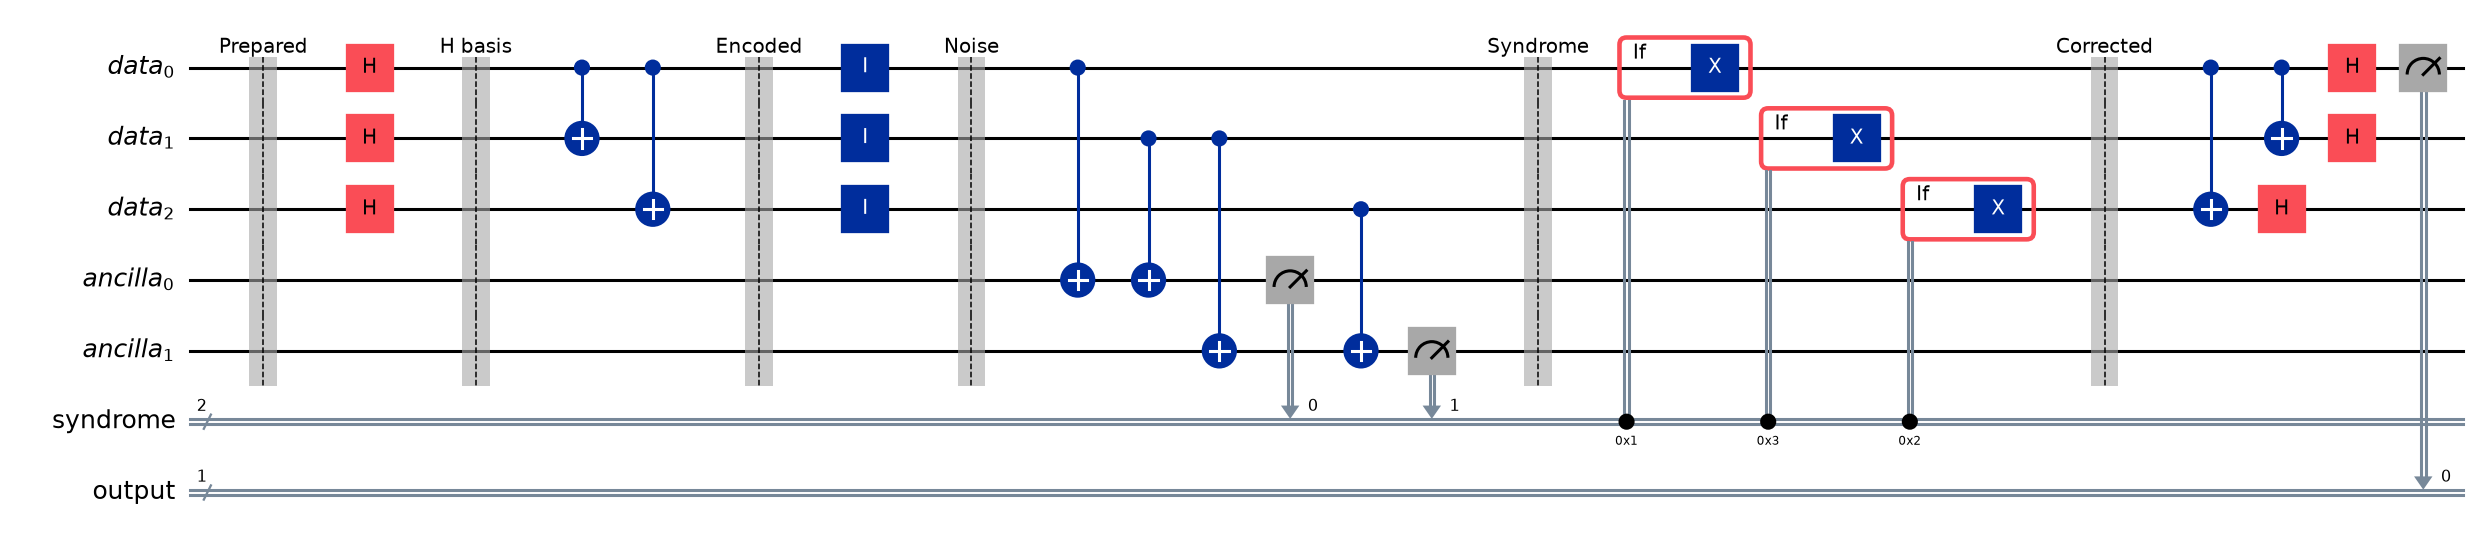

In [2]:
def build_phaseflip_circuit(initial_state='0', add_noise_gate=True):
    """
    Build the full 3-qubit phase-flip error correction circuit.
    
    This is the bit-flip code wrapped in Hadamard gates.
    H converts phase-flips into bit-flips, so the same correction works.
    """
    
    # === CREATE REGISTERS (same as bit-flip) ===
    data = QuantumRegister(3, 'data')
    ancilla = QuantumRegister(2, 'ancilla')
    syndrome_bits = ClassicalRegister(2, 'syndrome')
    output_bit = ClassicalRegister(1, 'output')
    
    circuit = QuantumCircuit(data, ancilla, syndrome_bits, output_bit)
    
    # ==========================================
    # STAGE 1: PREPARE THE INITIAL STATE
    # ==========================================
    if initial_state == '1':
        circuit.x(data[0])
    elif initial_state == '+':
        circuit.h(data[0])
    
    circuit.barrier(label='Prepared')
    
    # ==========================================
    # STAGE 2: HADAMARD ALL DATA QUBITS         ← NEW (not in bit-flip code)
    # ==========================================
    # This converts the phase-flip basis to the bit-flip basis
    # After this, a phase-flip (Z error) will look like a bit-flip (X error)
    circuit.h(data[0])   # ← NEW
    circuit.h(data[1])   # ← NEW
    circuit.h(data[2])   # ← NEW
    
    circuit.barrier(label='H basis')
    
    # ==========================================
    # STAGE 3: ENCODING (same as bit-flip)
    # ==========================================
    circuit.cx(data[0], data[1])
    circuit.cx(data[0], data[2])
    
    circuit.barrier(label='Encoded')
    
    # ==========================================
    # STAGE 4: NOISE (same as bit-flip)
    # ==========================================
    if add_noise_gate:
        circuit.id(data[0])
        circuit.id(data[1])
        circuit.id(data[2])
    
    circuit.barrier(label='Noise')
    
    # ==========================================
    # STAGE 5: SYNDROME MEASUREMENT (same as bit-flip)
    # ==========================================
    circuit.cx(data[0], ancilla[0])
    circuit.cx(data[1], ancilla[0])
    
    circuit.cx(data[1], ancilla[1])
    circuit.cx(data[2], ancilla[1])
    
    circuit.measure(ancilla[0], syndrome_bits[0])
    circuit.measure(ancilla[1], syndrome_bits[1])
    
    circuit.barrier(label='Syndrome')
    
    # ==========================================
    # STAGE 6: ERROR CORRECTION (same as bit-flip)
    # ==========================================
    # Qiskit 2.x removed InstructionSet.c_if() — use if_test instead
    with circuit.if_test((syndrome_bits, 1)):
        circuit.x(data[0])  # Syndrome 01 → fix data[0]
    with circuit.if_test((syndrome_bits, 3)):
        circuit.x(data[1])  # Syndrome 11 → fix data[1]
    with circuit.if_test((syndrome_bits, 2)):
        circuit.x(data[2])  # Syndrome 10 → fix data[2]
    
    circuit.barrier(label='Corrected')
    
    # ==========================================
    # STAGE 7: DECODING (same as bit-flip)
    # ==========================================
    circuit.cx(data[0], data[2])
    circuit.cx(data[0], data[1])
    
    # ==========================================
    # STAGE 8: UNDO HADAMARD                     ← NEW (not in bit-flip code)
    # ==========================================
    # Convert back from bit-flip basis to phase-flip basis
    circuit.h(data[0])   # ← NEW
    circuit.h(data[1])   # ← NEW
    circuit.h(data[2])   # ← NEW
    
    # Measure the original data qubit
    circuit.measure(data[0], output_bit[0])
    
    return circuit


# Build and display
example = build_phaseflip_circuit('0')
print(f'Total qubits: {example.num_qubits} (3 data + 2 ancilla)')
print(f'Only difference from bit-flip: Hadamard gates before encoding and after decoding')
print()
example.draw('mpl', fold=40)

---
## Step 3: Noise Models

Same noise models as before. Note: for the phase-flip code, we're particularly interested
in how it handles **depolarizing noise** (which includes Z errors that the bit-flip code can't catch).

In [3]:
def make_bit_flip_noise(p):
    error = pauli_error([('X', p), ('I', 1 - p)])
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(error, ['id'])
    return nm

def make_depolarizing_noise(p):
    error = depolarizing_error(p, 1)
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(error, ['id'])
    return nm

def make_amplitude_damping_noise(gamma):
    error = amplitude_damping_error(gamma)
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(error, ['id'])
    return nm

noise_makers = {
    'Bit-Flip':          make_bit_flip_noise,
    'Depolarizing':      make_depolarizing_noise,
    'Amplitude Damping': make_amplitude_damping_noise,
}

print('Noise models ready!')

Noise models ready!


---
## Step 4: Sanity Check

In [4]:
# Quick test: prepare |0⟩, apply 10% depolarizing noise (which includes phase-flips)
noise_prob = 0.10
shots = 5000

# WITH phase-flip correction
corrected_circuit = build_phaseflip_circuit('0')
noisy_sim = AerSimulator(noise_model=make_depolarizing_noise(noise_prob))
corrected_counts = noisy_sim.run(corrected_circuit, shots=shots).result().get_counts()

# output_bit is the first register in the bitstring (created after syndrome_bits,
# and Qiskit lists the most-recently-created classical register leftmost)
corrected_errors = sum(count for bitstring, count in corrected_counts.items()
                       if bitstring.split()[0] == '1')
corrected_error_rate = corrected_errors / shots

# WITHOUT correction
bare_circuit = QuantumCircuit(1, 1)
bare_circuit.id(0)
bare_circuit.measure(0, 0)

bare_sim = AerSimulator(noise_model=make_depolarizing_noise(noise_prob))
bare_counts = bare_sim.run(bare_circuit, shots=shots).result().get_counts()
bare_errors = bare_counts.get('1', 0)
bare_error_rate = bare_errors / shots

print(f'Physical error rate (no correction):  {bare_error_rate:.4f}')
print(f'Logical error rate (with correction):  {corrected_error_rate:.4f}')
print()
if corrected_error_rate < bare_error_rate:
    improvement = (1 - corrected_error_rate / bare_error_rate) * 100
    print(f'The code HELPED! Error reduced by {improvement:.1f}%')
else:
    print('The code did NOT help at this noise level')

Physical error rate (no correction):  0.0484
Logical error rate (with correction):  0.1420

The code did NOT help at this noise level


---
## Step 5: Full Experiment — Logical vs Physical Error Rate

In [5]:
noise_levels = [0.001, 0.005, 0.01, 0.02, 0.05, 0.08, 0.10, 0.12, 0.15, 0.18, 0.20]
shots = 10000
test_states = ['0', '1']


def get_logical_error_rate(initial_state, noise_type, noise_prob, num_shots):
    """Run phase-flip correction and measure how often the output is wrong."""
    circuit = build_phaseflip_circuit(initial_state)
    noise_model = noise_makers[noise_type](noise_prob)
    sim = AerSimulator(noise_model=noise_model)
    counts = sim.run(circuit, shots=num_shots).result().get_counts()
    
    wrong_output = '1' if initial_state == '0' else '0'
    errors = sum(count for bitstring, count in counts.items()
                 if bitstring.split()[0] == wrong_output)
    return errors / num_shots


def get_physical_error_rate(initial_state, noise_type, noise_prob, num_shots):
    """Run bare qubit (no correction) as baseline."""
    circuit = QuantumCircuit(1, 1)
    if initial_state == '1':
        circuit.x(0)
    circuit.id(0)
    circuit.measure(0, 0)
    
    noise_model = noise_makers[noise_type](noise_prob)
    sim = AerSimulator(noise_model=noise_model)
    counts = sim.run(circuit, shots=num_shots).result().get_counts()
    
    wrong_output = '1' if initial_state == '0' else '0'
    return counts.get(wrong_output, 0) / num_shots


# === RUN ALL EXPERIMENTS ===
all_results = []

for noise_type in noise_makers:
    for state in test_states:
        for p in noise_levels:
            logical_err = get_logical_error_rate(state, noise_type, p, shots)
            physical_err = get_physical_error_rate(state, noise_type, p, shots)
            
            all_results.append({
                'noise_type': noise_type,
                'initial_state': f'|{state}⟩',
                'noise_prob': p,
                'physical_error_rate': round(physical_err, 5),
                'logical_error_rate': round(logical_err, 5),
                'code_helps': logical_err < physical_err,
            })

print(f'Done! Ran {len(all_results)} experiments.')
results_df = pd.DataFrame(all_results)
results_df.head(10)

Done! Ran 66 experiments.


,noise_type,initial_state,noise_prob,physical_error_rate,logical_error_rate,code_helps
0,Bit-Flip,|0⟩,0.001,0.0006,0.0,True
1,Bit-Flip,|0⟩,0.005,0.0055,0.0,True
2,Bit-Flip,|0⟩,0.010,0.0093,0.0,True
3,Bit-Flip,|0⟩,0.020,0.0215,0.0,True
4,Bit-Flip,|0⟩,0.050,0.0503,0.0,True
5,Bit-Flip,|0⟩,0.080,0.0789,0.0,True
6,Bit-Flip,|0⟩,0.100,0.1004,0.0,True
7,Bit-Flip,|0⟩,0.120,0.1250,0.0,True
8,Bit-Flip,|0⟩,0.150,0.1508,0.0,True
9,Bit-Flip,|0⟩,0.180,0.1760,0.0,True


---
## Step 6: Plot Physical vs Logical Error Rate

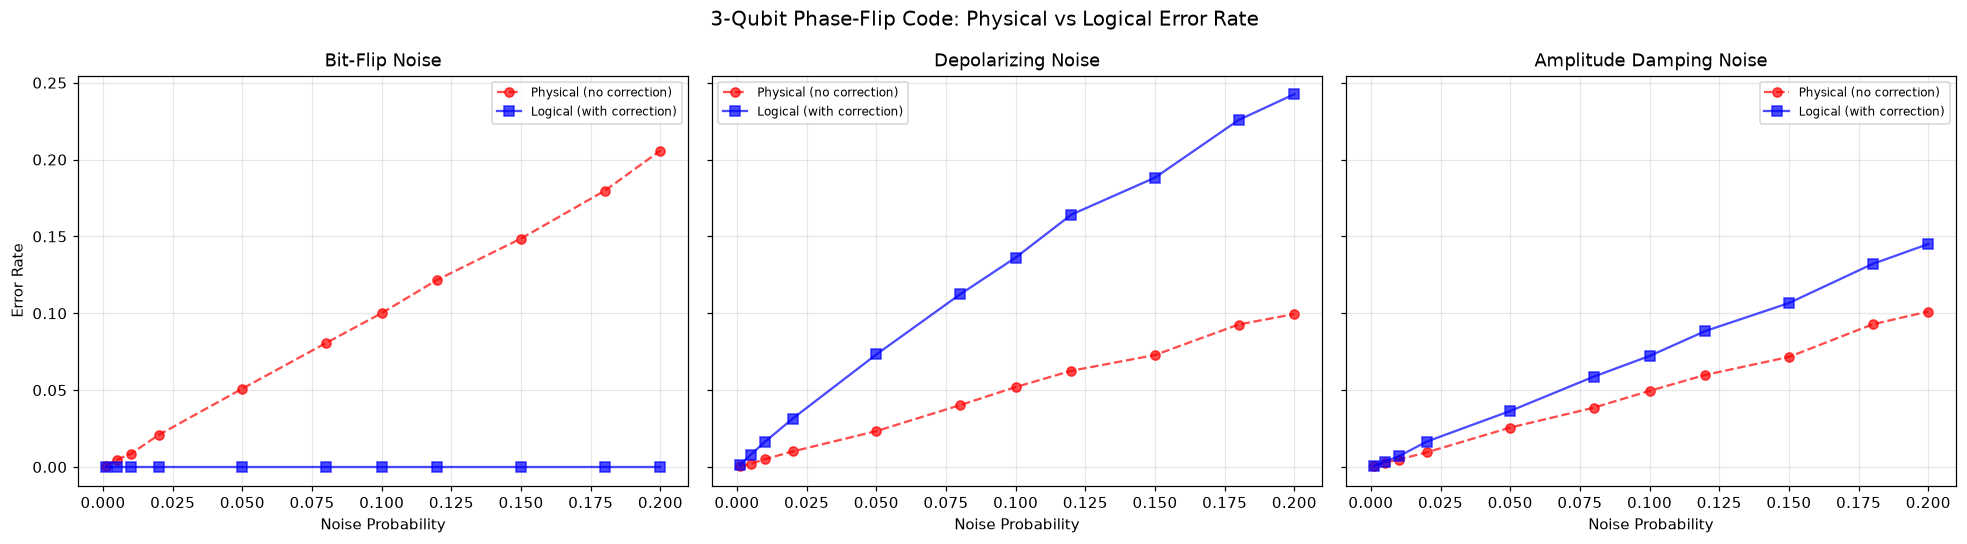

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, noise_type in zip(axes, noise_makers):
    subset = results_df[results_df.noise_type == noise_type]
    avg = subset.groupby('noise_prob').agg({
        'physical_error_rate': 'mean',
        'logical_error_rate': 'mean'
    }).reset_index()
    
    ax.plot(avg.noise_prob, avg.physical_error_rate, 
            'r--o', label='Physical (no correction)', alpha=0.7)
    ax.plot(avg.noise_prob, avg.logical_error_rate, 
            'b-s', label='Logical (with correction)', alpha=0.7)
    
    ax.set_title(f'{noise_type} Noise')
    ax.set_xlabel('Noise Probability')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel('Error Rate')
fig.suptitle('3-Qubit Phase-Flip Code: Physical vs Logical Error Rate', fontsize=13)
fig.tight_layout()

import os
os.makedirs('outputs/Phase2_PhaseFlip_Code', exist_ok=True)
fig.savefig('outputs/Phase2_PhaseFlip_Code/phaseflip_physical_vs_logical.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Step 7: Find the Pseudo-Threshold

In [7]:
print('Pseudo-Threshold Estimates (Phase-Flip Code)')
print('=' * 55)

for noise_type in noise_makers:
    subset = results_df[results_df.noise_type == noise_type]
    avg = subset.groupby('noise_prob').agg({
        'physical_error_rate': 'mean',
        'logical_error_rate': 'mean'
    }).reset_index()
    
    threshold_found = False
    for i in range(1, len(avg)):
        phys_prev = avg.iloc[i-1]['physical_error_rate']
        phys_curr = avg.iloc[i]['physical_error_rate']
        log_prev = avg.iloc[i-1]['logical_error_rate']
        log_curr = avg.iloc[i]['logical_error_rate']
        
        if log_prev <= phys_prev and log_curr >= phys_curr:
            p_low = avg.iloc[i-1]['noise_prob']
            p_high = avg.iloc[i]['noise_prob']
            diff_prev = phys_prev - log_prev
            diff_curr = log_curr - phys_curr
            threshold = p_low + (p_high - p_low) * diff_prev / (diff_prev + diff_curr)
            print(f'{noise_type:20s} → Pseudo-threshold ≈ {threshold:.4f} ({threshold*100:.2f}%)')
            threshold_found = True
            break
    
    if not threshold_found:
        always_helps = all(avg.logical_error_rate <= avg.physical_error_rate)
        if always_helps:
            print(f'{noise_type:20s} → Code always helps in tested range (threshold > 20%)')
        else:
            print(f'{noise_type:20s} → Code never helps (threshold < 0.1%)')

Pseudo-Threshold Estimates (Phase-Flip Code)
Bit-Flip             → Code always helps in tested range (threshold > 20%)
Depolarizing         → Code never helps (threshold < 0.1%)
Amplitude Damping    → Pseudo-threshold ≈ 0.0027 (0.27%)


---
## Step 8: Fidelity Analysis

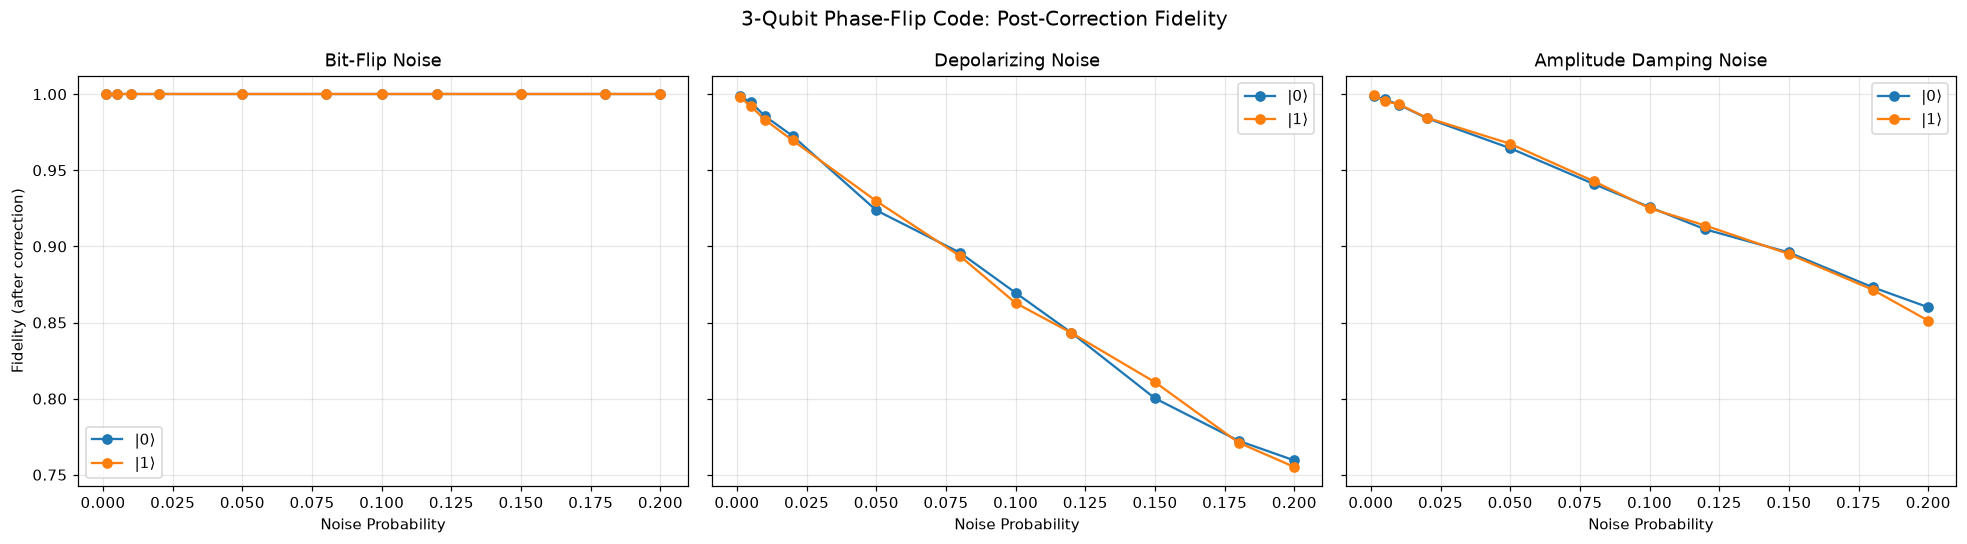

In [8]:
fidelity_results = []

for noise_type in noise_makers:
    for state in ['0', '1']:
        for p in noise_levels:
            circuit = build_phaseflip_circuit(state)
            noise_model = noise_makers[noise_type](p)
            sim = AerSimulator(noise_model=noise_model)
            counts = sim.run(circuit, shots=10000).result().get_counts()
            
            correct_output = '0' if state == '0' else '1'
            correct_count = sum(count for bitstring, count in counts.items()
                                if bitstring.split()[0] == correct_output)
            fidelity = correct_count / 10000
            
            fidelity_results.append({
                'noise_type': noise_type,
                'initial_state': f'|{state}⟩',
                'noise_prob': p,
                'fidelity_corrected': round(fidelity, 4)
            })

fidelity_df = pd.DataFrame(fidelity_results)

# Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, noise_type in zip(axes, noise_makers):
    subset = fidelity_df[fidelity_df.noise_type == noise_type]
    for state_name, group in subset.groupby('initial_state'):
        ax.plot(group.noise_prob, group.fidelity_corrected, marker='o', label=state_name)
    ax.set_title(f'{noise_type} Noise')
    ax.set_xlabel('Noise Probability')
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel('Fidelity (after correction)')
fig.suptitle('3-Qubit Phase-Flip Code: Post-Correction Fidelity', fontsize=13)
fig.tight_layout()

import os
os.makedirs('outputs/Phase2_PhaseFlip_Code', exist_ok=True)
fig.savefig('outputs/Phase2_PhaseFlip_Code/phaseflip_fidelity_post_correction.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Step 9: Save Results

In [9]:
import os
os.makedirs('outputs/Phase2_PhaseFlip_Code', exist_ok=True)
results_df.to_csv('outputs/Phase2_PhaseFlip_Code/phaseflip_error_rates.csv', index=False)
fidelity_df.to_csv('outputs/Phase2_PhaseFlip_Code/phaseflip_fidelity_results.csv', index=False)

print('Saved: outputs/Phase2_PhaseFlip_Code/phaseflip_error_rates.csv')
print('Saved: outputs/Phase2_PhaseFlip_Code/phaseflip_fidelity_results.csv')
print()
print('Phase-Flip Code notebook complete!')
print('Next: 9-Qubit Shor Code notebook')

Saved: outputs/Phase2_PhaseFlip_Code/phaseflip_error_rates.csv
Saved: outputs/Phase2_PhaseFlip_Code/phaseflip_fidelity_results.csv

Phase-Flip Code notebook complete!
Next: 9-Qubit Shor Code notebook
